# Object Removal — Single End-to-End Benchmark Notebook

This notebook is the **single entry point** for benchmarking the object-removal architectures discussed for Model 1.

### What it does
- Tests **10 COCO val2017 images** containing exactly one instance of the selected target class.
- Supports a **custom image** with the same text prompt.
- Every successful run returns and saves **mask, segmented overlay, and removed image**.
- Measures **grounding, segmentation, inpainting, and total latency**.
- Computes **mask IoU and Dice** against the COCO instance mask.
- Produces all comparison graphs at the end and writes CSV/PNG outputs.
- Runs architectures lazily so the notebook does not load every large model into memory at once.
- A missing optional model is recorded as `unavailable` instead of crashing the benchmark.

> **Important:** inpainting quality cannot be fairly scored against the original COCO image because the original contains the object. The notebook therefore reports segmentation quality + runtime, and uses pixel-change only as a diagnostic, not as an inpainting-quality score.

## Architectures included

### Existing / baseline pipelines
1. **YOLO26n-seg → LaMa**
2. **MobileSAM → LaMa**
3. **EfficientSAM-S → LaMa**
4. **Grounding DINO-Tiny → EfficientSAM-S → LaMa**
5. **Grounding DINO-Tiny → MobileSAM → LaMa**
6. **Grounding DINO-Tiny → EfficientSAM-S → MI-GAN**
7. **Grounding DINO-Tiny → EfficientSAM-S → PowerPaint v2-1** *(CUDA only; optional because it is very large)*

### Three additional controlled combinations
8. **Grounding DINO → YOLO26n-seg → LaMa**
9. **Grounding DINO → EfficientSAM-S → MI-GAN** *(same as #6, retained as the explicit proposed combination)*
10. **Grounding DINO → EfficientSAM-S → adaptive-LaMa** *(object-size-dependent mask dilation)*

The notebook treats #6 and #9 as the same architecture internally and de-duplicates the benchmark.

## 1. Configuration — change only this cell

In [1]:
# ================= USER CONFIG =================
TARGET_CLASS = "person"     # e.g. "bottle", "car", "dog", "chair"
CUSTOM_IMAGE = None          # e.g. "/Users/you/Desktop/test.jpg"

# Run all lightweight pipelines. PowerPaint is attempted only when CUDA is available.
RUN_ALL = True
ARCHITECTURES = [
    "YOLO26n-seg + LaMa",
    "MobileSAM + LaMa",
    "EfficientSAM-S + LaMa",
    "DINO + EfficientSAM-S + LaMa",
    "DINO + MobileSAM + LaMa",
    "DINO + EfficientSAM-S + MI-GAN",
    "DINO + YOLO26n-seg + LaMa",
    "DINO + EfficientSAM-S + adaptive LaMa",
    "DINO + EfficientSAM-S + PowerPaint v2-1",
]

N_COCO = 10
MASK_DILATION = 11
ADAPTIVE_DILATION_SCALE = 0.025
DINO_BOX_THRESHOLD = 0.25
DINO_TEXT_THRESHOLD = 0.20
SEED = 42

# PowerPaint is large. Set True only if you explicitly want to download/use it.
ALLOW_POWERPAINT = True

print("Target:", TARGET_CLASS)
print("Custom image:", CUSTOM_IMAGE)
print("Requested architectures:", len(ARCHITECTURES))

Target: person
Custom image: None
Requested architectures: 9


## 2. Install dependencies

Run this cell once in a fresh environment. Restart the kernel after installation if your notebook environment asks you to.

In [2]:
import sys, subprocess, importlib.util, os, platform

packages = [
    "numpy<3", "pillow>=10", "opencv-python-headless", "matplotlib", "pandas",
    "onnxruntime", "pycocotools", "transformers>=4.45", "accelerate",
    "safetensors", "ultralytics", "huggingface_hub"
]

subprocess.run([sys.executable, "-m", "pip", "install", "-q", *packages], check=True)

# MobileSAM is only installed if needed. This keeps the baseline environment smaller.
if any("MobileSAM" in x for x in ARCHITECTURES):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "git+https://github.com/ChaoningZhang/MobileSAM.git"], check=True)

print("Dependencies ready.")

Dependencies ready.


## 3. Imports, directories, device, and deterministic timing

In [3]:
from pathlib import Path
import os, time, math, json, urllib.request, zipfile, warnings
import numpy as np
import pandas as pd
import cv2
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

ROOT = Path.cwd()
DATA = ROOT / "object_removal_data"
MODELS = ROOT / "object_removal_models"
OUT = ROOT / "object_removal_outputs"
for p in [DATA, MODELS, OUT]:
    p.mkdir(parents=True, exist_ok=True)

import torch
if torch.cuda.is_available():
    DEVICE = "cuda"
elif getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("Torch device:", DEVICE)
print("Output directory:", OUT.resolve())

def sync_device():
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    elif DEVICE == "mps":
        try: torch.mps.synchronize()
        except Exception: pass

def timed(fn, *args, **kwargs):
    sync_device(); t0 = time.perf_counter()
    result = fn(*args, **kwargs)
    sync_device()
    return result, (time.perf_counter() - t0) * 1000

def load_rgb(path):
    return Image.open(path).convert("RGB")

def as_np(image):
    return np.asarray(image.convert("RGB"))

def binary(mask):
    if isinstance(mask, Image.Image): mask = np.asarray(mask)
    mask = np.asarray(mask)
    if mask.ndim == 3: mask = mask[..., 0]
    return (mask > 0).astype(np.uint8)

def cleanup_mask(mask, min_area=80):
    m = (binary(mask) * 255).astype(np.uint8)
    n, labels, stats, _ = cv2.connectedComponentsWithStats(m, 8)
    if n <= 1: return (m > 0).astype(np.uint8)
    idx = 1 + int(np.argmax(stats[1:, cv2.CC_STAT_AREA]))
    largest = (labels == idx).astype(np.uint8)
    if int(largest.sum()) < min_area: return (m > 0).astype(np.uint8)
    return largest

def dilate_mask(mask, k=11):
    k = max(1, int(k)); k += (k % 2 == 0)
    kernel = np.ones((k, k), np.uint8)
    return (cv2.dilate(binary(mask) * 255, kernel, iterations=1) > 0).astype(np.uint8)

def adaptive_dilate(mask):
    area = max(1, int(binary(mask).sum()))
    diameter = max(5, int(2 * math.sqrt(area / math.pi) * ADAPTIVE_DILATION_SCALE))
    if diameter % 2 == 0: diameter += 1
    return dilate_mask(mask, diameter)

def overlay_mask(image, mask, alpha=0.45):
    a = as_np(image).copy(); m = binary(mask).astype(bool)
    red = np.zeros_like(a); red[..., 0] = 255
    a[m] = (a[m] * (1-alpha) + red[m] * alpha).astype(np.uint8)
    return Image.fromarray(a)

def draw_box(image, box, label=None):
    out = image.copy(); d = ImageDraw.Draw(out)
    d.rectangle(tuple(map(int, box)), outline=(255,0,0), width=max(2, out.width//300))
    if label: d.text((int(box[0]), max(0,int(box[1])-18)), label, fill=(255,0,0))
    return out

def bbox_from_mask(mask, pad=0.65):
    m = binary(mask); ys, xs = np.where(m > 0)
    if len(xs) == 0: return (0,0,m.shape[1],m.shape[0])
    x0,x1,y0,y1 = xs.min(),xs.max()+1,ys.min(),ys.max()+1
    w,h = x1-x0,y1-y0
    px,py = max(8,int(w*pad)),max(8,int(h*pad))
    return (max(0,x0-px),max(0,y0-py),min(m.shape[1],x1+px),min(m.shape[0],y1+py))

def feather_composite(original, generated, mask, radius=2):
    a = as_np(original).astype(np.float32)
    b = as_np(generated.resize(original.size)).astype(np.float32)
    m = (binary(mask)*255).astype(np.uint8)
    if radius: m = cv2.GaussianBlur(m, (0,0), radius)
    alpha = (m.astype(np.float32)/255.0)[...,None]
    out = b*alpha + a*(1-alpha)
    return Image.fromarray(np.clip(out,0,255).astype(np.uint8))

def iou(pred, gt):
    p,g = binary(pred).astype(bool),binary(gt).astype(bool)
    u = np.logical_or(p,g).sum()
    return float(np.logical_and(p,g).sum()/u) if u else 0.0

def dice(pred, gt):
    p,g = binary(pred).astype(bool),binary(gt).astype(bool)
    d = p.sum()+g.sum()
    return float(2*np.logical_and(p,g).sum()/d) if d else 0.0

def change_score(original, removed, mask):
    m = binary(mask).astype(bool)
    a,b = as_np(original).astype(np.float32),as_np(removed).astype(np.float32)
    return float(np.abs(a[m]-b[m]).mean()) if m.any() else 0.0

def save_outputs(image, mask, removed, prefix, box=None):
    base = OUT / prefix
    base.mkdir(parents=True, exist_ok=True)
    Image.fromarray((binary(mask)*255).astype(np.uint8)).save(base/"mask.png")
    overlay_mask(image,mask).save(base/"segmented.png")
    removed.save(base/"removed.png")
    if box is not None: draw_box(image,box).save(base/"box.png")
    return base

Python: 3.13.15
PyTorch: 2.11.0+cpu
Torch device: cpu
Output directory: /content/object_removal_outputs


## 4. Download and verify core model weights

This cell downloads only the lightweight/local weights. YOLO downloads its checkpoint automatically on first construction. Grounding DINO downloads through Transformers on first construction.

In [4]:
def download(url, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists() and path.stat().st_size > 1024:
        print("[exists]", path)
        return path
    print("[download]", url)
    urllib.request.urlretrieve(url, path)
    print("[saved]", path, f"({path.stat().st_size/1024/1024:.1f} MB)")
    return path

# EfficientSAM official split ONNX
if any("EfficientSAM" in x for x in ARCHITECTURES):
    download("https://huggingface.co/yunyangx/EfficientSAM/resolve/main/efficientsam_s_encoder.onnx", MODELS/"efficient_sam/encoder.onnx")
    download("https://huggingface.co/yunyangx/EfficientSAM/resolve/main/efficientsam_s_decoder.onnx", MODELS/"efficient_sam/decoder.onnx")

# MobileSAM official checkpoint
if any("MobileSAM" in x for x in ARCHITECTURES):
    download("https://github.com/ChaoningZhang/MobileSAM/raw/master/weights/mobile_sam.pt", MODELS/"mobile_sam.pt")

# LaMa ONNX
if any("LaMa" in x for x in ARCHITECTURES):
    download("https://huggingface.co/Carve/LaMa-ONNX/resolve/main/lama_fp32.onnx", MODELS/"lama_fp32.onnx")

# MI-GAN ONNX
if any("MI-GAN" in x for x in ARCHITECTURES):
    download("https://huggingface.co/andraniksargsyan/migan/resolve/main/migan_pipeline_v2.onnx", MODELS/"migan_pipeline_v2.onnx")

print("Core download step complete.")

[download] https://huggingface.co/yunyangx/EfficientSAM/resolve/main/efficientsam_s_encoder.onnx
[saved] /content/object_removal_models/efficient_sam/encoder.onnx (85.4 MB)
[download] https://huggingface.co/yunyangx/EfficientSAM/resolve/main/efficientsam_s_decoder.onnx
[saved] /content/object_removal_models/efficient_sam/decoder.onnx (15.8 MB)
[download] https://github.com/ChaoningZhang/MobileSAM/raw/master/weights/mobile_sam.pt
[saved] /content/object_removal_models/mobile_sam.pt (38.8 MB)
[download] https://huggingface.co/Carve/LaMa-ONNX/resolve/main/lama_fp32.onnx
[saved] /content/object_removal_models/lama_fp32.onnx (198.4 MB)
[download] https://huggingface.co/andraniksargsyan/migan/resolve/main/migan_pipeline_v2.onnx
[saved] /content/object_removal_models/migan_pipeline_v2.onnx (26.8 MB)
Core download step complete.


## 5. COCO 10-image selector

The selector chooses 10 `val2017` images containing **exactly one non-crowd instance** of the requested class. This avoids ambiguous ground truth when measuring segmentation.

In [5]:
COCO_IMG_URL = "http://images.cocodataset.org/val2017/{:012d}.jpg"
COCO_ANN_URL = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"

def download_coco_annotations():
    ann = DATA/"coco/annotations/instances_val2017.json"
    if ann.exists(): return ann
    z = DATA/"annotations_trainval2017.zip"
    download(COCO_ANN_URL, z)
    with zipfile.ZipFile(z) as f:
        f.extract("annotations/instances_val2017.json", DATA/"coco")
    return ann

def select_coco_10(target_class, n=10):
    from pycocotools.coco import COCO
    ann = download_coco_annotations(); coco = COCO(str(ann))
    cat_ids = coco.getCatIds(catNms=[target_class])
    if not cat_ids: raise ValueError(f"Unknown COCO class: {target_class}")
    image_ids = []
    for iid in coco.getImgIds(catIds=cat_ids):
        anns = coco.loadAnns(coco.getAnnIds(imgIds=[iid], catIds=cat_ids, iscrowd=False))
        if len(anns) == 1:
            image_ids.append(iid)
        if len(image_ids) >= n: break
    records=[]
    for iid in image_ids:
        p=DATA/"coco10"/f"{iid:012d}.jpg"
        download(COCO_IMG_URL.format(iid),p)
        ann0=coco.loadAnns(coco.getAnnIds(imgIds=[iid],catIds=cat_ids,iscrowd=False))[0]
        gt=coco.annToMask(ann0).astype(np.uint8)
        x,y,w,h=ann0["bbox"]
        records.append({"id":iid,"path":str(p),"gt_mask":gt,"bbox":[x,y,x+w,y+h],"class":target_class})
    if len(records)<n:
        print(f"Warning: found only {len(records)} suitable images for {target_class}.")
    return records

records = select_coco_10(TARGET_CLASS, N_COCO)
print("COCO benchmark images:", len(records))
print([r["id"] for r in records])

[download] http://images.cocodataset.org/annotations/annotations_trainval2017.zip
[saved] /content/object_removal_data/annotations_trainval2017.zip (241.2 MB)
loading annotations into memory...
Done (t=1.82s)
creating index...
index created!
[download] http://images.cocodataset.org/val2017/000000385029.jpg
[saved] /content/object_removal_data/coco10/000000385029.jpg (0.2 MB)
[download] http://images.cocodataset.org/val2017/000000311303.jpg
[saved] /content/object_removal_data/coco10/000000311303.jpg (0.1 MB)
[download] http://images.cocodataset.org/val2017/000000393226.jpg
[saved] /content/object_removal_data/coco10/000000393226.jpg (0.2 MB)
[download] http://images.cocodataset.org/val2017/000000532493.jpg
[saved] /content/object_removal_data/coco10/000000532493.jpg (0.2 MB)
[download] http://images.cocodataset.org/val2017/000000188439.jpg
[saved] /content/object_removal_data/coco10/000000188439.jpg (0.3 MB)
[download] http://images.cocodataset.org/val2017/000000401446.jpg
[saved] /con

## 6. Model wrappers

All wrappers expose the same contract:

```text
segment(image, target_class) -> {mask, box, score}
inpaint(image, mask) -> removed_image
```

Models are instantiated lazily later.

In [6]:
class GroundingDINO:
    def __init__(self):
        from transformers import AutoProcessor, AutoModelForZeroShotObjectDetection
        self.processor = AutoProcessor.from_pretrained("IDEA-Research/grounding-dino-tiny")
        self.model = AutoModelForZeroShotObjectDetection.from_pretrained("IDEA-Research/grounding-dino-tiny").to(DEVICE).eval()
    def predict(self,image,text):
        q=text.lower().strip()
        if not q.endswith("."): q += "."
        inputs=self.processor(images=image,text=q,return_tensors="pt").to(DEVICE)
        with torch.no_grad(): outputs=self.model(**inputs)
        size=torch.tensor([image.size[::-1]],device=outputs.logits.device)
        try:
            r=self.processor.post_process_grounded_object_detection(outputs,inputs.input_ids,threshold=DINO_BOX_THRESHOLD,text_threshold=DINO_TEXT_THRESHOLD,target_sizes=size)[0]
        except TypeError:
            r=self.processor.image_processor.post_process_object_detection(outputs,threshold=DINO_BOX_THRESHOLD,target_sizes=size)[0]
        if len(r["boxes"])==0: return None
        i=int(torch.argmax(r["scores"]).item())
        return {"box":r["boxes"][i].detach().cpu().numpy().tolist(),"score":float(r["scores"][i].detach().cpu()),"label":str(r.get("labels",[text])[i])}

class EfficientSAM:
    def __init__(self):
        import onnxruntime as ort
        self.enc=ort.InferenceSession(str(MODELS/"efficient_sam/encoder.onnx"),providers=["CPUExecutionProvider"])
        self.dec=ort.InferenceSession(str(MODELS/"efficient_sam/decoder.onnx"),providers=["CPUExecutionProvider"])
        self.enc_in=self.enc.get_inputs()[0].name
    def predict_box(self,image,box):
        arr=as_np(image).astype(np.float32); h,w=arr.shape[:2]
        emb=self.enc.run(None,{self.enc_in:arr.transpose(2,0,1)[None]/255.0})[0]
        pts=np.array([[[[box[0],box[1]],[box[2],box[3]]]]],np.float32)
        labels=np.array([[[2,3]]],np.float32)
        feed={"image_embeddings":emb,"batched_point_coords":pts,"batched_point_labels":labels,"orig_im_size":np.array([h,w],np.int64)}
        out=self.dec.run(None,feed)
        logits,ious=out[0],out[1]
        flat_iou=np.asarray(ious).reshape(-1); best=int(np.argmax(flat_iou))
        flat_logits=np.asarray(logits).reshape(-1,logits.shape[-2],logits.shape[-1])
        m=(flat_logits[best]>=0).astype(np.uint8)
        if m.shape!=(h,w): m=cv2.resize(m,(w,h),interpolation=cv2.INTER_NEAREST)
        return m

class MobileSAM:
    def __init__(self):
        from mobile_sam import sam_model_registry, SamPredictor
        self.model=sam_model_registry["vit_t"](checkpoint=str(MODELS/"mobile_sam.pt")).to(DEVICE).eval()
        self.predictor=SamPredictor(self.model)
    def predict_box(self,image,box):
        self.predictor.set_image(as_np(image))
        masks,_,_=self.predictor.predict(box=np.asarray(box,dtype=np.float32),multimask_output=True)
        # For a box prompt, choose the largest plausible mask.
        return masks[int(np.argmax([m.sum() for m in masks]))].astype(np.uint8)

class YOLO26Seg:
    def __init__(self):
        from ultralytics import YOLO
        self.model=YOLO("yolo26n-seg.pt")
    def predict(self,image,target_class,box=None):
        dev=0 if DEVICE=="cuda" else ("mps" if DEVICE=="mps" else "cpu")
        r=self.model.predict(source=as_np(image),verbose=False,device=dev)[0]
        if r.masks is None or len(r.masks.data)==0: return None
        names=r.names; candidates=[]
        for i,(cls,conf) in enumerate(zip(r.boxes.cls.cpu().numpy(),r.boxes.conf.cpu().numpy())):
            if names[int(cls)].lower()!=target_class.lower(): continue
            bx=r.boxes.xyxy[i].cpu().numpy().tolist()
            m=(r.masks.data[i].cpu().numpy()>0.5).astype(np.uint8)
            if box is not None:
                # Prefer the YOLO instance whose box overlaps the DINO box most.
                xa=max(box[0],bx[0]); ya=max(box[1],bx[1]); xb=min(box[2],bx[2]); yb=min(box[3],bx[3])
                inter=max(0,xb-xa)*max(0,yb-ya); ua=max(1,(box[2]-box[0])*(box[3]-box[1])+(bx[2]-bx[0])*(bx[3]-bx[1])-inter)
                score=inter/ua
            else: score=float(conf)
            candidates.append((score,m,bx,float(conf)))
        if not candidates:return None
        candidates.sort(key=lambda x:x[0],reverse=True)
        _,m,bx,conf=candidates[0]
        return {"mask":cleanup_mask(m),"box":bx,"score":conf}

class LaMaONNX:
    def __init__(self):
        import onnxruntime as ort
        self.sess=ort.InferenceSession(str(MODELS/"lama_fp32.onnx"),providers=["CPUExecutionProvider"])
    def inpaint(self,image,mask):
        img=as_np(image); m=binary(mask)
        x0,y0,x1,y1=bbox_from_mask(m,0.65)
        roi=img[y0:y1,x0:x1]; rm=m[y0:y1,x0:x1]
        im=cv2.resize(roi,(512,512),interpolation=cv2.INTER_AREA).astype(np.float32)/255.0
        mm=cv2.resize(rm,(512,512),interpolation=cv2.INTER_NEAREST).astype(np.float32)
        out=self.sess.run(None,{"image":im.transpose(2,0,1)[None],"mask":mm[None,None]})[0][0]
        if out.max()<=1.5: out*=255.0
        gen=np.clip(out.transpose(1,2,0),0,255).astype(np.uint8)
        gen=cv2.resize(gen,(roi.shape[1],roi.shape[0]),interpolation=cv2.INTER_CUBIC)
        canvas=img.copy(); canvas[y0:y1,x0:x1]=gen
        return feather_composite(image,Image.fromarray(canvas),m,2)

class MIGANONNX:
    def __init__(self):
        import onnxruntime as ort
        self.sess=ort.InferenceSession(str(MODELS/"migan_pipeline_v2.onnx"),providers=["CPUExecutionProvider"])
        self.names=[x.name for x in self.sess.get_inputs()]
    def inpaint(self,image,mask):
        img=as_np(image); m=(binary(mask)*255).astype(np.uint8)
        out=self.sess.run(None,{self.names[0]:img[None],self.names[1]:m[None]})[0]
        arr=np.asarray(out)
        if arr.ndim==4: arr=arr[0]
        if arr.shape[0] in (1,3): arr=arr.transpose(1,2,0)
        arr=np.clip(arr,0,255).astype(np.uint8)
        if arr.shape[:2]!=img.shape[:2]: arr=cv2.resize(arr,(img.shape[1],img.shape[0]),interpolation=cv2.INTER_CUBIC)
        return Image.fromarray(arr)

## 7. Lazy model registry

Only the models needed by a selected architecture are loaded. This is important on a 16 GB Mac and also prevents unrelated model-loading failures from stopping the rest of the benchmark.

In [7]:
_CACHE={}
def get_model(key):
    if key in _CACHE: return _CACHE[key]
    if key=="dino": obj=GroundingDINO()
    elif key=="effsam": obj=EfficientSAM()
    elif key=="mobilesam": obj=MobileSAM()
    elif key=="yolo": obj=YOLO26Seg()
    elif key=="lama": obj=LaMaONNX()
    elif key=="migan": obj=MIGANONNX()
    else: raise KeyError(key)
    _CACHE[key]=obj
    return obj

ARCH_DEFS = {
    "YOLO26n-seg + LaMa": ["yolo","lama"],
    "MobileSAM + LaMa": ["yolo","mobilesam","lama"],
    "EfficientSAM-S + LaMa": ["yolo","effsam","lama"],
    "DINO + EfficientSAM-S + LaMa": ["dino","effsam","lama"],
    "DINO + MobileSAM + LaMa": ["dino","mobilesam","lama"],
    "DINO + EfficientSAM-S + MI-GAN": ["dino","effsam","migan"],
    "DINO + YOLO26n-seg + LaMa": ["dino","yolo","lama"],
    "DINO + EfficientSAM-S + adaptive LaMa": ["dino","effsam","lama"],
    "DINO + EfficientSAM-S + PowerPaint v2-1": ["dino","effsam"],
}

print("Architecture registry ready.")

Architecture registry ready.


## 8. Segmentation and inpainting dispatchers

In [8]:
def segment_for(architecture, image):
    t0=time.perf_counter(); box=None; score=None
    dino_box=None
    if architecture.startswith("DINO"):
        d=get_model("dino").predict(image,TARGET_CLASS)
        if d is None: return None,(time.perf_counter()-t0)*1000,None,None
        dino_box=d["box"]; box=d["box"]; score=d["score"]
    if architecture.startswith("YOLO26"):
        r=get_model("yolo").predict(image,TARGET_CLASS)
        if r is None:return None,(time.perf_counter()-t0)*1000,None,None
        return cleanup_mask(r["mask"]),(time.perf_counter()-t0)*1000,r["box"],r["score"]
    if "DINO + YOLO" in architecture:
        r=get_model("yolo").predict(image,TARGET_CLASS,box=dino_box)
        if r is None:return None,(time.perf_counter()-t0)*1000,dino_box,score
        return cleanup_mask(r["mask"]),(time.perf_counter()-t0)*1000,r["box"],score
    if "MobileSAM" in architecture:
        if box is None:
            y=get_model("yolo").predict(image,TARGET_CLASS)
            if y is None:return None,(time.perf_counter()-t0)*1000,None,None
            box=y["box"]
        m=get_model("mobilesam").predict_box(image,box)
        return cleanup_mask(m),(time.perf_counter()-t0)*1000,box,score
    if "EfficientSAM-S" in architecture:
        if box is None:
            y=get_model("yolo").predict(image,TARGET_CLASS)
            if y is None:return None,(time.perf_counter()-t0)*1000,None,None
            box=y["box"]
        m=get_model("effsam").predict_box(image,box)
        return cleanup_mask(m),(time.perf_counter()-t0)*1000,box,score
    raise ValueError(architecture)

def inpaint_for(architecture,image,mask):
    if "PowerPaint" in architecture:
        return powerpaint_inpaint(image,mask)
    if "MI-GAN" in architecture:
        return get_model("migan").inpaint(image,mask)
    if "adaptive LaMa" in architecture:
        return get_model("lama").inpaint(image,adaptive_dilate(mask))
    return get_model("lama").inpaint(image,dilate_mask(mask,MASK_DILATION))

## 9. Optional PowerPaint v2-1 backend

PowerPaint is deliberately isolated. If CUDA is unavailable or the official package/checkpoint is not present, the benchmark records it as unavailable and continues with every other architecture. This prevents one large optional model from breaking the whole notebook.

In [9]:
POWERPAINT_READY=False
powerpaint_controller=None

def try_prepare_powerpaint():
    global POWERPAINT_READY, powerpaint_controller
    if not ALLOW_POWERPAINT or DEVICE!="cuda":
        print("PowerPaint skipped: CUDA is required by this notebook backend.")
        return False
    try:
        import sys, subprocess, shutil
        repo=ROOT/"PowerPaint"
        if not repo.exists():
            subprocess.run(["git","clone","https://github.com/open-mmlab/PowerPaint.git",str(repo)],check=True)
        subprocess.run([sys.executable,"-m","pip","install","-q","-r",str(repo/"requirements/requirements.txt")],check=True)
        # The official v2-1 checkpoint is large; use Hugging Face snapshot_download.
        from huggingface_hub import snapshot_download
        ckpt=MODELS/"PowerPaint-v2-1"
        if not ckpt.exists():
            snapshot_download(repo_id="JunhaoZhuang/PowerPaint-v2-1",local_dir=str(ckpt))
        sys.path.insert(0,str(repo))
        from app import PowerPaintController
        powerpaint_controller=PowerPaintController(str(ckpt))
        POWERPAINT_READY=True
        print("PowerPaint ready.")
        return True
    except Exception as e:
        POWERPAINT_READY=False
        print("PowerPaint unavailable:",repr(e))
        return False

def powerpaint_inpaint(image,mask):
    if not POWERPAINT_READY:
        raise RuntimeError("PowerPaint is not ready. Run try_prepare_powerpaint() on a CUDA machine.")
    m=(binary(mask)*255).astype(np.uint8)
    inp={"image":image.convert("RGB"),"mask":Image.fromarray(m).convert("RGB")}
    # Official PowerPaint controller API used by its object-removal demo.
    out,_=powerpaint_controller.predict(inp,"empty prompt",None,seed=SEED,steps=30,guidance_scale=12.0,task="object-removal")
    return out.convert("RGB")

if "DINO + EfficientSAM-S + PowerPaint v2-1" in ARCHITECTURES and ALLOW_POWERPAINT:
    try_prepare_powerpaint()

PowerPaint skipped: CUDA is required by this notebook backend.


## 10. One-image runner

Every architecture produces the same result dictionary. The custom-image path uses the same code as the COCO benchmark, so it is not a separate implementation.

In [10]:
def run_one(architecture, image_path, gt_mask=None, image_id=None):
    image=load_rgb(image_path)
    result={"architecture":architecture,"id":image_id,"path":str(image_path),"success":False}
    t0=time.perf_counter()
    try:
        mask,seg_ms,box,score=segment_for(architecture,image)
        result.update({"segmentation_ms":seg_ms,"box":box,"grounding_score":score})
        if mask is None:
            result["error"]="No target detected/segmented"
            result["total_ms"]=(time.perf_counter()-t0)*1000
            return result
        ip_t=time.perf_counter()
        removed=inpaint_for(architecture,image,mask)
        inp_ms=(time.perf_counter()-ip_t)*1000
        total=(time.perf_counter()-t0)*1000
        result.update({"success":True,"inpainting_ms":inp_ms,"total_ms":total,
                       "mask_area_px":int(binary(mask).sum()),
                       "mask_area_pct":float(binary(mask).mean()*100),
                       "change_score":change_score(image,removed,mask)})
        if gt_mask is not None:
            result["iou"]=iou(mask,gt_mask); result["dice"]=dice(mask,gt_mask)
        prefix=f"{architecture.replace(' ','_').replace('+','plus').replace('/','_')}/{Path(image_path).stem}"
        save_outputs(image,mask,removed,prefix,box)
        result["mask"]=mask; result["removed"]=removed
        return result
    except Exception as e:
        result["error"]=f"{type(e).__name__}: {e}"
        result["total_ms"]=(time.perf_counter()-t0)*1000
        return result

def display_result(result):
    if not result.get("success"):
        print(result.get("error","failed")); return
    image=load_rgb(result["path"]); mask=result["mask"]; removed=result["removed"]
    fig,ax=plt.subplots(1,4,figsize=(16,4))
    ax[0].imshow(image); ax[0].set_title("Original")
    ax[1].imshow(mask,cmap="gray"); ax[1].set_title("Mask")
    ax[2].imshow(overlay_mask(image,mask)); ax[2].set_title("Segmented")
    ax[3].imshow(removed); ax[3].set_title("Removed")
    for a in ax:a.axis("off")
    plt.suptitle(result["architecture"]); plt.tight_layout(); plt.show()
    print({k:v for k,v in result.items() if k not in {"mask","removed"}})

## 11. Custom image test

Set `CUSTOM_IMAGE` in the configuration cell. If it is `None`, this section simply skips.

In [11]:
if CUSTOM_IMAGE:
    print("Running custom image:",CUSTOM_IMAGE)
    custom_results=[]
    for arch in ARCHITECTURES:
        if "PowerPaint" in arch and not POWERPAINT_READY: continue
        print("\n---",arch,"---")
        r=run_one(arch,CUSTOM_IMAGE)
        custom_results.append(r)
        display_result(r)
else:
    print("CUSTOM_IMAGE is None — skipped. Set it in Cell 3 to test your own image.")

CUSTOM_IMAGE is None — skipped. Set it in Cell 3 to test your own image.


## 12. Run the 10-image COCO benchmark

This is the main benchmark cell. A failed architecture/image is recorded as a row with `success=False`; the notebook does **not** abort the remaining architectures.

In [12]:
available_archs=[]
for arch in ARCHITECTURES:
    if "PowerPaint" in arch and not POWERPAINT_READY:
        print("[skip]",arch,"— PowerPaint unavailable")
        continue
    available_archs.append(arch)

all_rows=[]
for arch in available_archs:
    print("\n" + "="*90 + "\n", arch, "\n" + "="*90)
    for j,rec in enumerate(records,1):
        r=run_one(arch,rec["path"],gt_mask=rec["gt_mask"],image_id=rec["id"])
        row={k:v for k,v in r.items() if k not in {"mask","removed","box"}}
        all_rows.append(row)
        status="OK" if r.get("success") else "FAIL"
        print(f"[{j:02d}/{len(records)}] {status} image={rec['id']} total={r.get('total_ms',0):.1f} ms", end="")
        if r.get("success"): print(f" IoU={r.get('iou',0):.3f} Dice={r.get('dice',0):.3f}")
        else: print(" ",r.get("error",""))

results_df=pd.DataFrame(all_rows)
results_df.to_csv(OUT/"all_benchmark_results.csv",index=False)
print("\nSaved:",OUT/"all_benchmark_results.csv")
display(results_df.head())

[skip] DINO + EfficientSAM-S + PowerPaint v2-1 — PowerPaint unavailable

 YOLO26n-seg + LaMa 
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
[01/10] OK image=385029 total=69268.5 ms IoU=0.943 Dice=0.971
[02/10] FAIL image=311303 total=13103.5 ms  ValueError: operands could not be broadcast together with shapes (427,640,3) (448,640,1) 
[03/10] OK image=393226 total=12763.8 ms IoU=0.853 Dice=0.921
[04/10] FAIL image=532493 total=12625.5 ms  ValueError: operands could not be broadcast together with shapes (408,640,3) (416,640,1) 
[05/10] FAIL image=188439 total=12919.3 ms  ValueError: operands could not be broadcast together with shapes (408,640,3) (416,640,1) 
[06/10] OK image=401446 total=12691.4 ms IoU=0.720 Dice=0.837
[07/10] OK image=213033 t

preprocessor_config.json:   0%|          | 0.00/457 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.64k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.24k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  689MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/978 [00:00<?, ?it/s]

[01/10] OK image=385029 total=90258.0 ms IoU=0.933 Dice=0.965
[02/10] OK image=311303 total=60735.1 ms IoU=0.941 Dice=0.970
[03/10] OK image=393226 total=57344.6 ms IoU=0.870 Dice=0.930
[04/10] OK image=532493 total=62869.4 ms IoU=0.800 Dice=0.889
[05/10] OK image=188439 total=63273.3 ms IoU=0.687 Dice=0.814
[06/10] OK image=401446 total=57061.2 ms IoU=0.774 Dice=0.872
[07/10] OK image=213033 total=58366.3 ms IoU=0.889 Dice=0.941
[08/10] OK image=516143 total=57225.9 ms IoU=0.850 Dice=0.919
[09/10] OK image=475191 total=56754.3 ms IoU=0.908 Dice=0.952
[10/10] OK image=254016 total=62739.4 ms IoU=0.492 Dice=0.659

 DINO + MobileSAM + LaMa 
[01/10] OK image=385029 total=50193.3 ms IoU=0.841 Dice=0.913
[02/10] OK image=311303 total=52546.8 ms IoU=0.945 Dice=0.971
[03/10] OK image=393226 total=47928.4 ms IoU=0.872 Dice=0.932
[04/10] OK image=532493 total=54376.9 ms IoU=0.798 Dice=0.888
[05/10] OK image=188439 total=53914.8 ms IoU=0.645 Dice=0.784
[06/10] OK image=401446 total=49042.4 ms Io

,architecture,id,path,success,segmentation_ms,grounding_score,inpainting_ms,total_ms,mask_area_px,mask_area_pct,change_score,iou,dice,error
0,YOLO26n-seg + LaMa,385029,/content/object_removal_data/coco10/0000003850...,True,19100.610831,0.657813,50167.877913,69268.510768,18694.0,6.085286,36.517456,0.943215,0.970778,NaN
1,YOLO26n-seg + LaMa,311303,/content/object_removal_data/coco10/0000003113...,False,239.005510,0.419903,NaN,13103.506650,NaN,NaN,NaN,NaN,NaN,ValueError: operands could not be broadcast to...
2,YOLO26n-seg + LaMa,393226,/content/object_removal_data/coco10/0000003932...,True,251.030378,0.844845,12512.784839,12763.829102,4264.0,1.388021,83.188553,0.853020,0.920681,NaN
3,YOLO26n-seg + LaMa,532493,/content/object_removal_data/coco10/0000005324...,False,212.553166,0.840633,NaN,12625.515794,NaN,NaN,NaN,NaN,NaN,ValueError: operands could not be broadcast to...
4,YOLO26n-seg + LaMa,188439,/content/object_removal_data/coco10/0000001884...,False,187.000605,0.448850,NaN,12919.282536,NaN,NaN,NaN,NaN,NaN,ValueError: operands could not be broadcast to...


## 13. Aggregate benchmark table

In [13]:
if len(results_df):
    summary=(results_df.groupby("architecture",dropna=False)
             .agg(images=("id","count"),
                  success_rate=("success","mean"),
                  mean_iou=("iou","mean"),
                  mean_dice=("dice","mean"),
                  mean_segmentation_ms=("segmentation_ms","mean"),
                  mean_inpainting_ms=("inpainting_ms","mean"),
                  mean_total_ms=("total_ms","mean"),
                  mean_change_score=("change_score","mean"))
             .reset_index())
    summary.to_csv(OUT/"architecture_summary.csv",index=False)
    display(summary.sort_values("mean_total_ms"))
else:
    summary=pd.DataFrame(); print("No benchmark results.")

,architecture,images,success_rate,mean_iou,mean_dice,mean_segmentation_ms,mean_inpainting_ms,mean_total_ms,mean_change_score
6,MobileSAM + LaMa,10,0.9,0.809547,0.891937,3925.059307,12291.700101,14987.607180,61.525352
7,YOLO26n-seg + LaMa,10,0.6,0.847370,0.915794,2107.428070,19884.291804,17838.988842,56.818919
5,EfficientSAM-S + LaMa,10,0.9,0.826824,0.902610,11984.357312,12451.029296,23190.301453,61.677767
4,DINO + YOLO26n-seg + LaMa,10,0.6,0.847370,0.915794,36253.521658,12391.295050,47404.831362,56.818919
1,DINO + EfficientSAM-S + MI-GAN,10,0.0,NaN,NaN,48849.111163,NaN,48921.465616,NaN
3,DINO + MobileSAM + LaMa,10,1.0,0.804986,0.885425,38052.797951,12264.848920,50317.664864,61.840595
2,DINO + EfficientSAM-S + adaptive LaMa,10,1.0,0.814315,0.891217,49142.729038,12550.444428,61693.199656,55.724839
0,DINO + EfficientSAM-S + LaMa,10,1.0,0.814315,0.891217,49850.582712,12812.139500,62662.741895,60.857999


## 14. Graph 1 — mean total latency

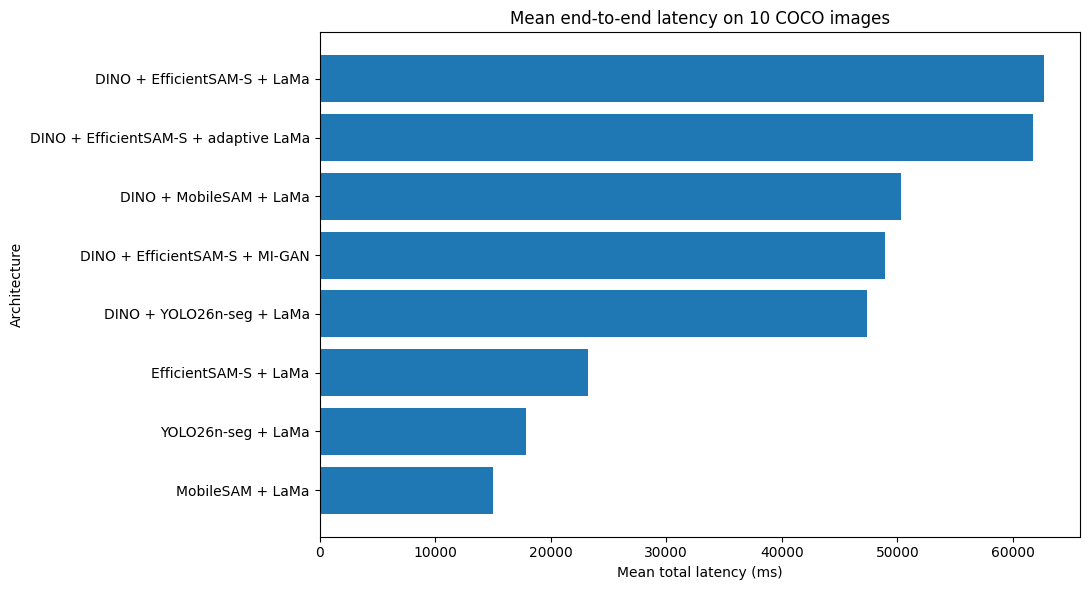

In [14]:
if len(summary):
    d=summary.sort_values("mean_total_ms")
    plt.figure(figsize=(11,6)); plt.barh(d["architecture"],d["mean_total_ms"])
    plt.xlabel("Mean total latency (ms)"); plt.ylabel("Architecture"); plt.title("Mean end-to-end latency on 10 COCO images")
    plt.tight_layout(); plt.savefig(OUT/"01_mean_total_latency.png",dpi=200); plt.show()

## 15. Graph 2 — segmentation vs inpainting latency

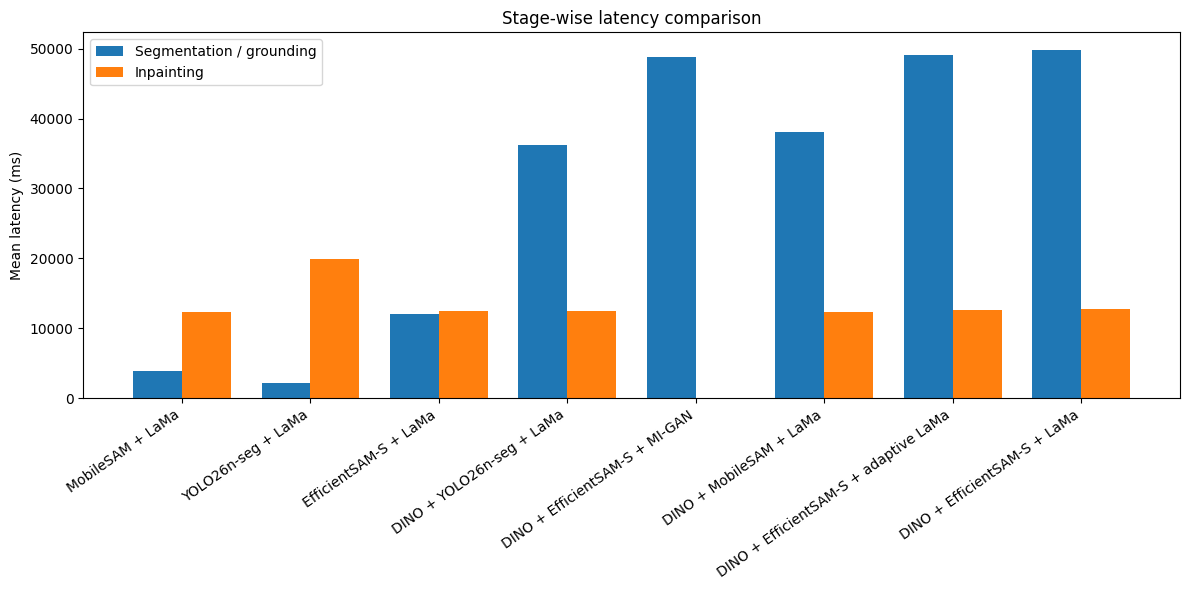

In [15]:
if len(summary):
    d=summary.sort_values("mean_total_ms")
    x=np.arange(len(d)); w=0.38
    plt.figure(figsize=(12,6)); plt.bar(x-w/2,d["mean_segmentation_ms"],w,label="Segmentation / grounding"); plt.bar(x+w/2,d["mean_inpainting_ms"],w,label="Inpainting")
    plt.xticks(x,d["architecture"],rotation=35,ha="right"); plt.ylabel("Mean latency (ms)"); plt.title("Stage-wise latency comparison"); plt.legend(); plt.tight_layout(); plt.savefig(OUT/"02_stage_latency.png",dpi=200); plt.show()

## 16. Graph 3 — segmentation quality: IoU and Dice

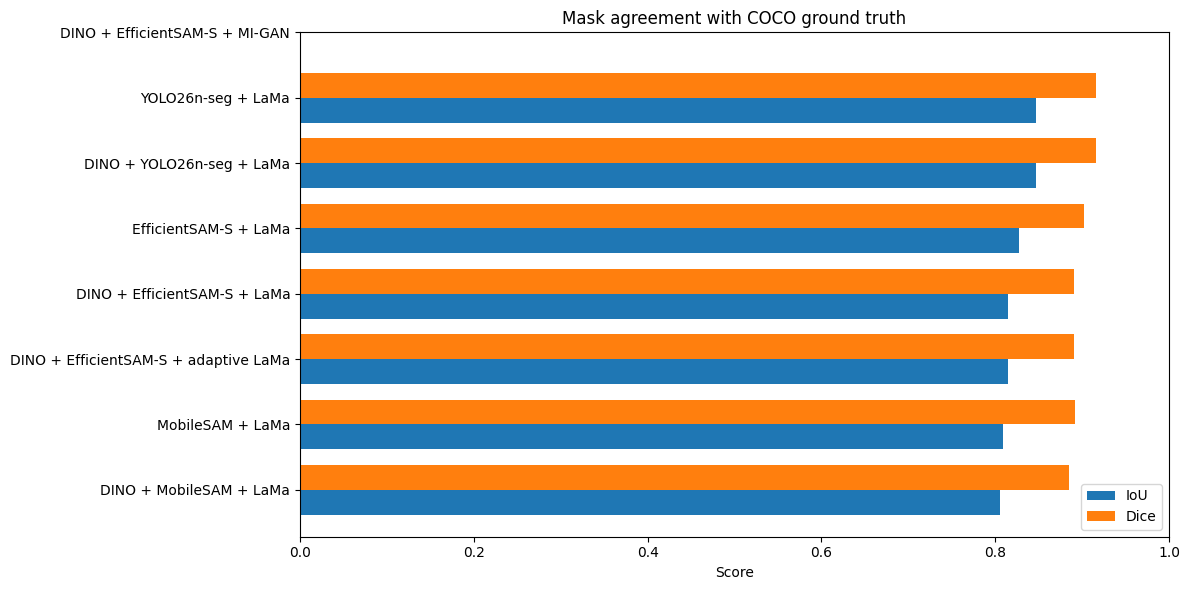

In [16]:
if len(summary):
    d=summary.sort_values("mean_iou",ascending=True)
    x=np.arange(len(d)); w=0.38
    plt.figure(figsize=(12,6)); plt.barh(x-w/2,d["mean_iou"],w,label="IoU"); plt.barh(x+w/2,d["mean_dice"],w,label="Dice")
    plt.yticks(x,d["architecture"]); plt.xlim(0,1); plt.xlabel("Score"); plt.title("Mask agreement with COCO ground truth"); plt.legend(); plt.tight_layout(); plt.savefig(OUT/"03_mask_quality.png",dpi=200); plt.show()

## 17. Graph 4 — quality vs latency scatter

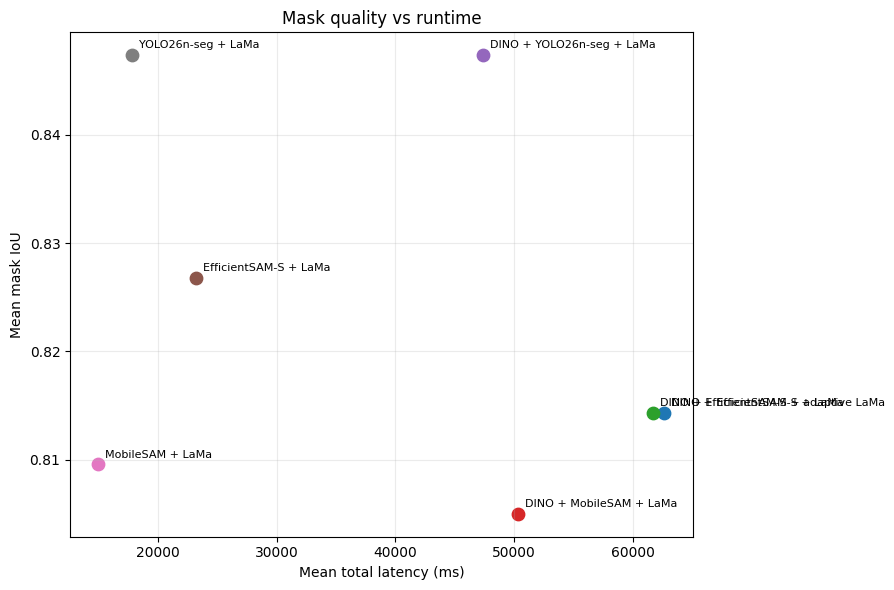

In [17]:
if len(summary):
    plt.figure(figsize=(9,6));
    for _,r in summary.iterrows():
        plt.scatter(r["mean_total_ms"],r["mean_iou"],s=80)
        plt.annotate(r["architecture"],(r["mean_total_ms"],r["mean_iou"]),xytext=(5,5),textcoords="offset points",fontsize=8)
    plt.xlabel("Mean total latency (ms)"); plt.ylabel("Mean mask IoU"); plt.title("Mask quality vs runtime")
    plt.grid(alpha=.25); plt.tight_layout(); plt.savefig(OUT/"04_quality_vs_latency.png",dpi=200); plt.show()

## 18. Graph 5 — success rate

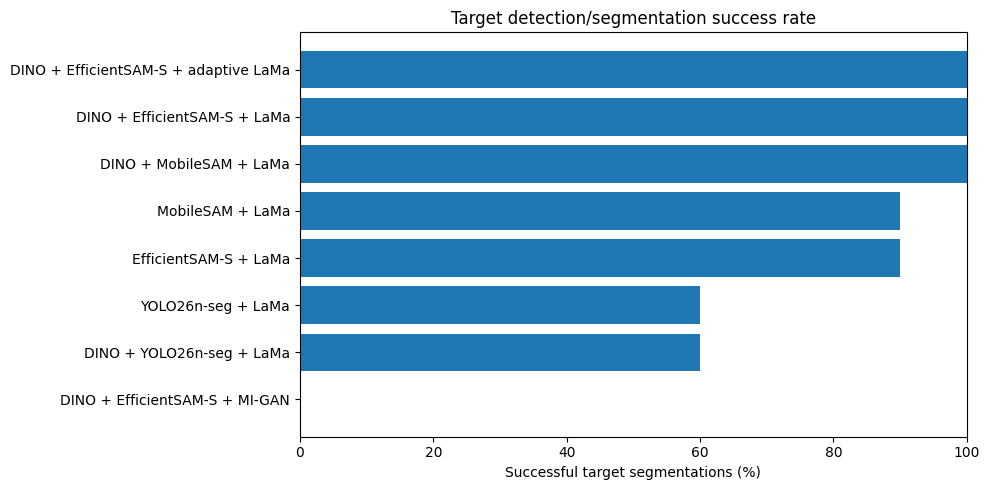

In [18]:
if len(summary):
    d=summary.sort_values("success_rate",ascending=True)
    plt.figure(figsize=(10,5)); plt.barh(d["architecture"],d["success_rate"]*100)
    plt.xlim(0,100); plt.xlabel("Successful target segmentations (%)"); plt.title("Target detection/segmentation success rate")
    plt.tight_layout(); plt.savefig(OUT/"05_success_rate.png",dpi=200); plt.show()

## 19. Per-image latency distribution

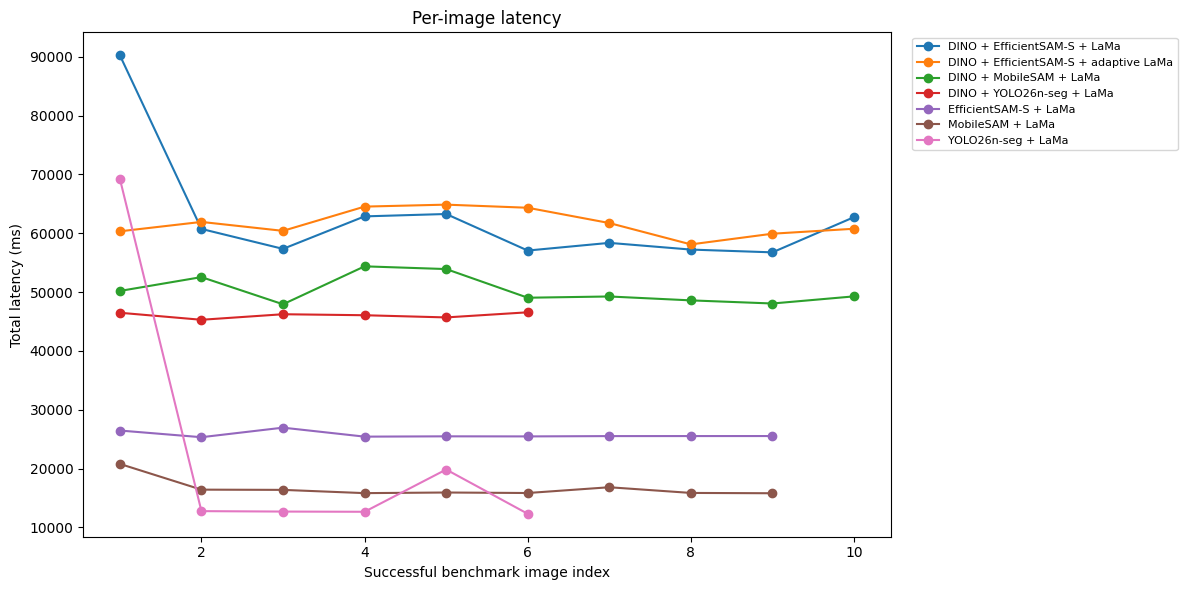

In [19]:
if len(results_df):
    plt.figure(figsize=(12,6))
    for arch,grp in results_df[results_df.success==True].groupby("architecture"):
        plt.plot(range(1,len(grp)+1),grp["total_ms"].values,marker="o",label=arch)
    plt.xlabel("Successful benchmark image index"); plt.ylabel("Total latency (ms)"); plt.title("Per-image latency"); plt.legend(bbox_to_anchor=(1.02,1),loc="upper left",fontsize=8); plt.tight_layout(); plt.savefig(OUT/"06_per_image_latency.png",dpi=200); plt.show()

## 20. Inspect one COCO image across architectures

Inspecting COCO image 385029


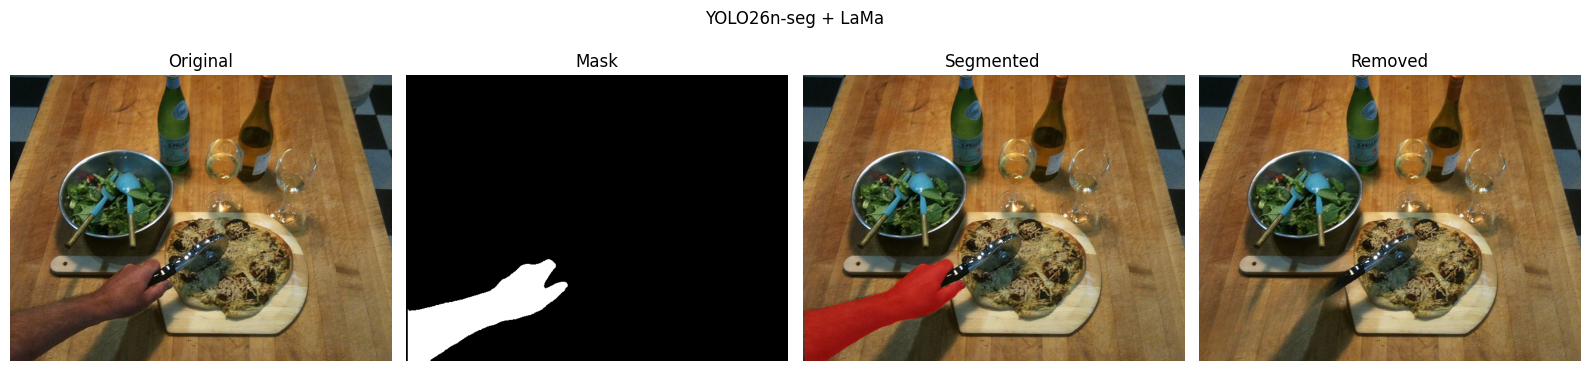

{'architecture': 'YOLO26n-seg + LaMa', 'id': 385029, 'path': '/content/object_removal_data/coco10/000000385029.jpg', 'success': True, 'segmentation_ms': 252.89752100024998, 'box': [2.042266845703125, 305.790771484375, 272.8921813964844, 479.4820556640625], 'grounding_score': 0.6578125357627869, 'inpainting_ms': 12614.260194000053, 'total_ms': 12867.179652000232, 'mask_area_px': 18694, 'mask_area_pct': 6.085286458333333, 'change_score': 36.5174560546875, 'iou': 0.9432148794679966, 'dice': 0.9707777451006604}


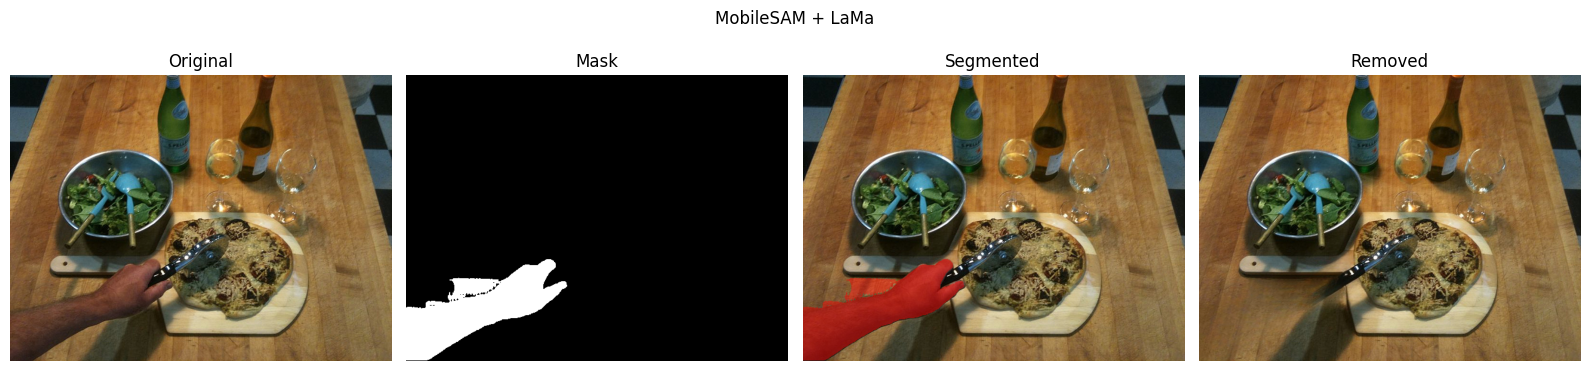

{'architecture': 'MobileSAM + LaMa', 'id': 385029, 'path': '/content/object_removal_data/coco10/000000385029.jpg', 'success': True, 'segmentation_ms': 4363.252720000219, 'box': [2.042266845703125, 305.790771484375, 272.8921813964844, 479.4820556640625], 'grounding_score': None, 'inpainting_ms': 12702.629732999412, 'total_ms': 17065.909935000036, 'mask_area_px': 20682, 'mask_area_pct': 6.732421875, 'change_score': 33.53786087036133, 'iou': 0.8418197970729883, 'dice': 0.9141174379934502}


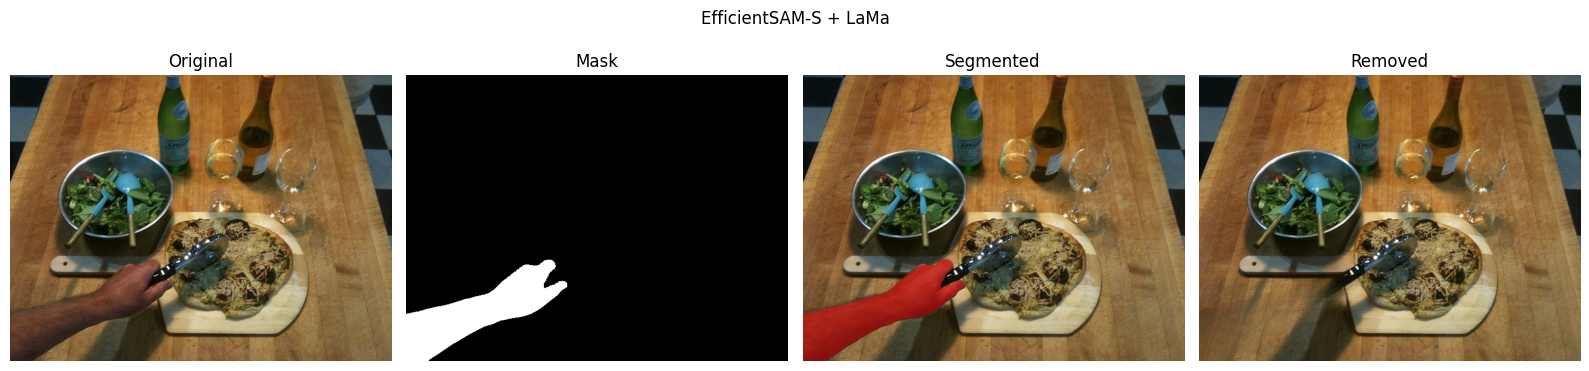

{'architecture': 'EfficientSAM-S + LaMa', 'id': 385029, 'path': '/content/object_removal_data/coco10/000000385029.jpg', 'success': True, 'segmentation_ms': 13214.293449999786, 'box': [2.042266845703125, 305.790771484375, 272.8921813964844, 479.4820556640625], 'grounding_score': None, 'inpainting_ms': 13084.376021000026, 'total_ms': 26298.688584000047, 'mask_area_px': 18000, 'mask_area_pct': 5.859375, 'change_score': 33.95920181274414, 'iou': 0.9331718363262942, 'dice': 0.9654308207796454}


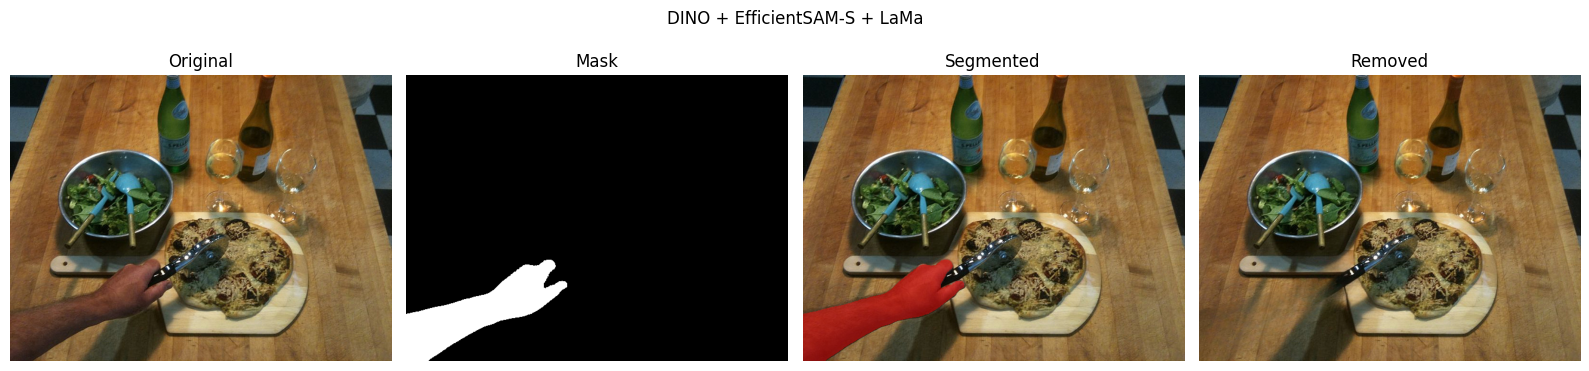

{'architecture': 'DINO + EfficientSAM-S + LaMa', 'id': 385029, 'path': '/content/object_removal_data/coco10/000000385029.jpg', 'success': True, 'segmentation_ms': 47216.04213699993, 'box': [0.22390365600585938, 307.19720458984375, 273.14947509765625, 479.491455078125], 'grounding_score': 0.7124893069267273, 'inpainting_ms': 12598.077661999923, 'total_ms': 59814.13992600028, 'mask_area_px': 17998, 'mask_area_pct': 5.858723958333333, 'change_score': 33.99324035644531, 'iou': 0.9331683168316832, 'dice': 0.9654289372599232}


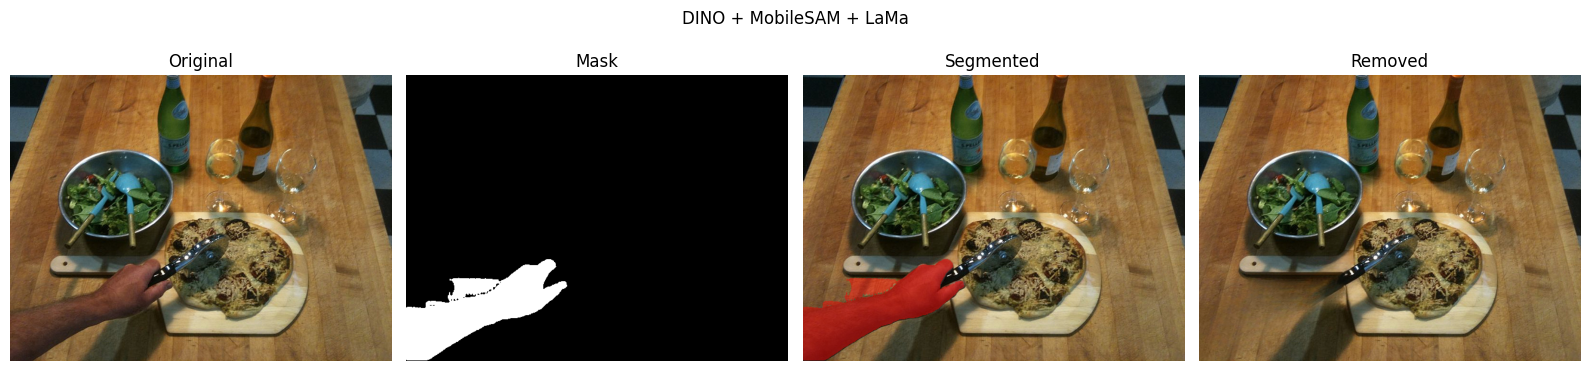

{'architecture': 'DINO + MobileSAM + LaMa', 'id': 385029, 'path': '/content/object_removal_data/coco10/000000385029.jpg', 'success': True, 'segmentation_ms': 37427.955940000174, 'box': [0.22390365600585938, 307.19720458984375, 273.14947509765625, 479.491455078125], 'grounding_score': 0.7124893069267273, 'inpainting_ms': 11800.338796999313, 'total_ms': 49228.31897600008, 'mask_area_px': 20730, 'mask_area_pct': 6.748046874999999, 'change_score': 34.148529052734375, 'iou': 0.8407075515728554, 'dice': 0.9134612946575724}


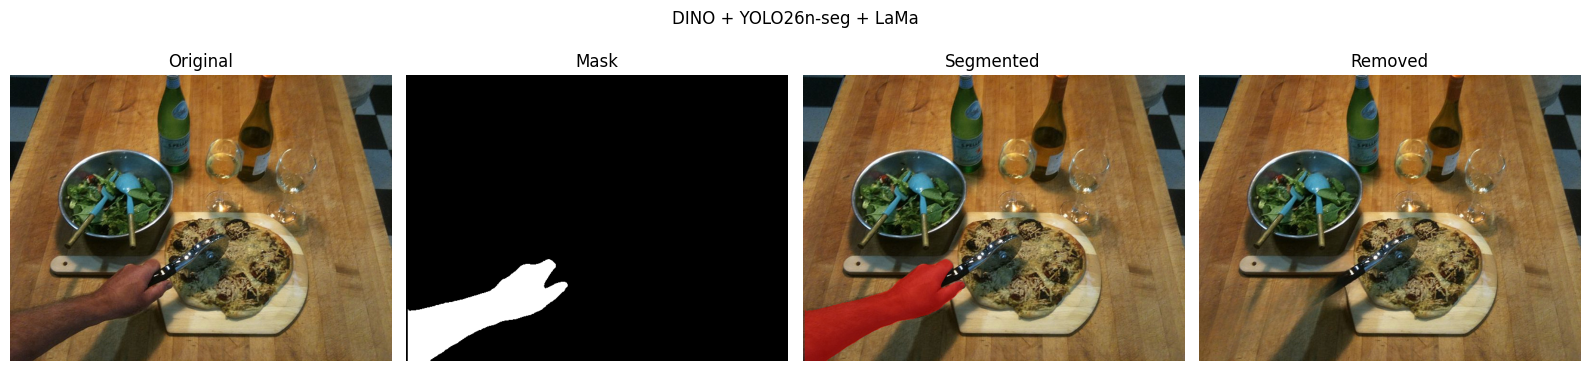

{'architecture': 'DINO + YOLO26n-seg + LaMa', 'id': 385029, 'path': '/content/object_removal_data/coco10/000000385029.jpg', 'success': True, 'segmentation_ms': 33196.37948899981, 'box': [2.042266845703125, 305.790771484375, 272.8921813964844, 479.4820556640625], 'grounding_score': 0.7124893069267273, 'inpainting_ms': 12231.789767999544, 'total_ms': 45428.19249199965, 'mask_area_px': 18694, 'mask_area_pct': 6.085286458333333, 'change_score': 36.5174560546875, 'iou': 0.9432148794679966, 'dice': 0.9707777451006604}


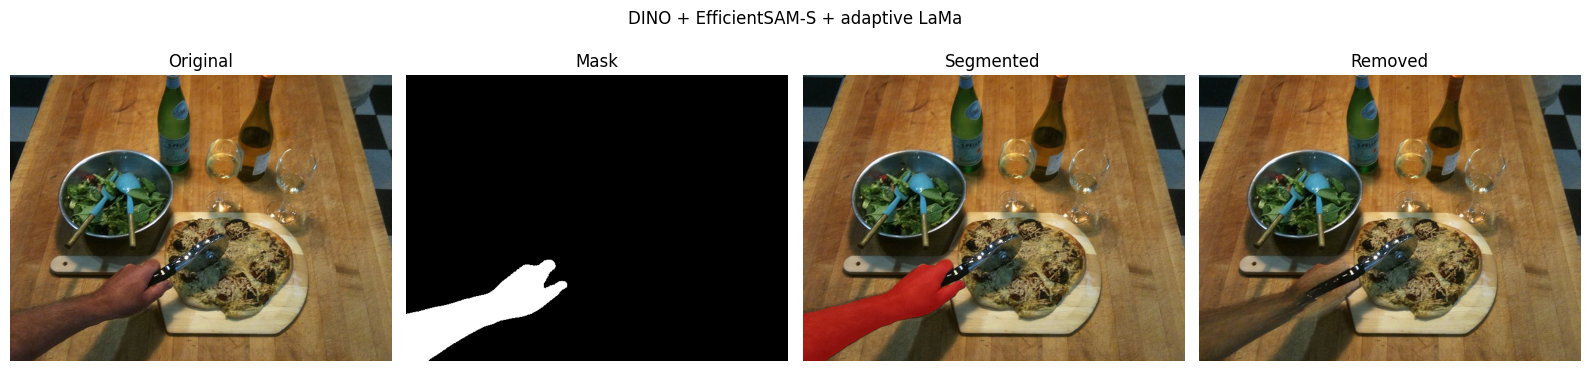

{'architecture': 'DINO + EfficientSAM-S + adaptive LaMa', 'id': 385029, 'path': '/content/object_removal_data/coco10/000000385029.jpg', 'success': True, 'segmentation_ms': 46388.179777000005, 'box': [0.22390365600585938, 307.19720458984375, 273.14947509765625, 479.491455078125], 'grounding_score': 0.7124893069267273, 'inpainting_ms': 12514.05958199939, 'total_ms': 58902.25825899961, 'mask_area_px': 17998, 'mask_area_pct': 5.858723958333333, 'change_score': 19.400192260742188, 'iou': 0.9331683168316832, 'dice': 0.9654289372599232}


In [20]:
if records:
    inspect_id=records[0]["id"]
    sub=results_df[results_df.id==inspect_id]
    print("Inspecting COCO image",inspect_id)
    for arch in available_archs:
        # Re-run only the selected image so we can display the actual outputs without storing images in the dataframe.
        rr=run_one(arch,records[0]["path"],gt_mask=records[0]["gt_mask"],image_id=inspect_id)
        if rr.get("success"):
            display_result(rr)

## 21. Final exported files

Everything needed for the report is under `object_removal_outputs/`:

```text
all_benchmark_results.csv
architecture_summary.csv
01_mean_total_latency.png
02_stage_latency.png
03_mask_quality.png
04_quality_vs_latency.png
05_success_rate.png
06_per_image_latency.png
<architecture>/<image>/mask.png
<architecture>/<image>/segmented.png
<architecture>/<image>/removed.png
```

For the final report, use **IoU/Dice for segmentation**, **latency for efficiency**, and describe `change_score` only as a diagnostic signal for whether the generator altered the masked region.

In [21]:
!zip -r /content/output.zip /content/object_removal_outputs

  adding: content/object_removal_outputs/ (stored 0%)
  adding: content/object_removal_outputs/06_per_image_latency.png (deflated 13%)
  adding: content/object_removal_outputs/architecture_summary.csv (deflated 51%)
  adding: content/object_removal_outputs/DINO_plus_YOLO26n-seg_plus_LaMa/ (stored 0%)
  adding: content/object_removal_outputs/DINO_plus_YOLO26n-seg_plus_LaMa/000000385029/ (stored 0%)
  adding: content/object_removal_outputs/DINO_plus_YOLO26n-seg_plus_LaMa/000000385029/mask.png (deflated 11%)
  adding: content/object_removal_outputs/DINO_plus_YOLO26n-seg_plus_LaMa/000000385029/removed.png (deflated 0%)
  adding: content/object_removal_outputs/DINO_plus_YOLO26n-seg_plus_LaMa/000000385029/box.png (deflated 0%)
  adding: content/object_removal_outputs/DINO_plus_YOLO26n-seg_plus_LaMa/000000385029/segmented.png (deflated 0%)
  adding: content/object_removal_outputs/DINO_plus_YOLO26n-seg_plus_LaMa/000000475191/ (stored 0%)
  adding: content/object_removal_outputs/DINO_plus_YOLO2